In [39]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

In [40]:
orders = pd.read_csv(
    "../data/processed/delivered_orders_clean.csv"
)

customers = pd.read_csv(
    "../data/processed/customers_clean.csv"
)

order_items = pd.read_csv(
    "../data/processed/order_items_clean.csv"
)

payments = pd.read_csv(
    "../data/processed/payments_clean.csv"
)

reviews = pd.read_csv(
    "../data/processed/reviews_clean.csv"
)

products = pd.read_csv(
    "../data/processed/products_clean.csv"
)

sellers = pd.read_csv(
    "../data/processed/sellers_clean.csv"
)

In [41]:
print("Orders:", orders.shape)
print("Customers:", customers.shape)
print("Order Items:", order_items.shape)
print("Payments:", payments.shape)
print("Reviews:", reviews.shape)
print("Products:", products.shape)
print("Sellers:", sellers.shape)

Orders: (96455, 9)
Customers: (99441, 5)
Order Items: (112650, 7)
Payments: (103886, 5)
Reviews: (99224, 8)
Products: (32951, 10)
Sellers: (3095, 4)


In [42]:
orders["order_status"].value_counts()

order_status
delivered    96455
Name: count, dtype: int64

In [43]:
orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"]
)

In [44]:
orders["purchase_month"] = (
    orders["order_purchase_timestamp"]
    .dt.to_period("M")
)

In [45]:
monthly_orders = (
    orders.groupby("purchase_month")
    .size()
)

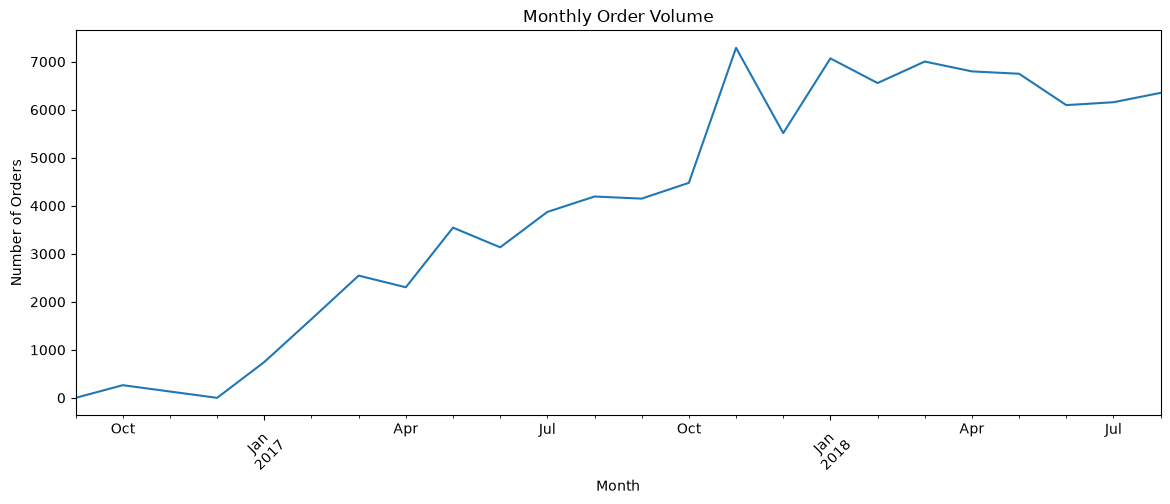

In [46]:
plt.figure(figsize=(14, 5))

monthly_orders.plot()

plt.title("Monthly Order Volume")
plt.xlabel("Month")
plt.ylabel("Number of Orders")

plt.xticks(rotation=45)
plt.show()

In [47]:
orders["delivery_days"].describe()

count    96455.000000
mean        12.557693
std          9.545982
min          0.533414
25%          6.765498
50%         10.216227
75%         15.720145
max        209.628611
Name: delivery_days, dtype: float64

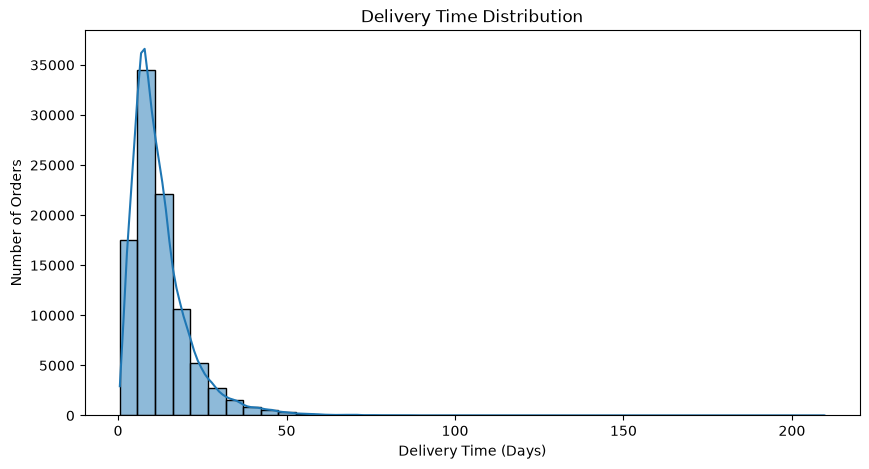

In [48]:
plt.figure(figsize=(10, 5))

sns.histplot(
    orders["delivery_days"],
    bins=40,
    kde=True
)

plt.title("Delivery Time Distribution")
plt.xlabel("Delivery Time (Days)")
plt.ylabel("Number of Orders")

plt.show()

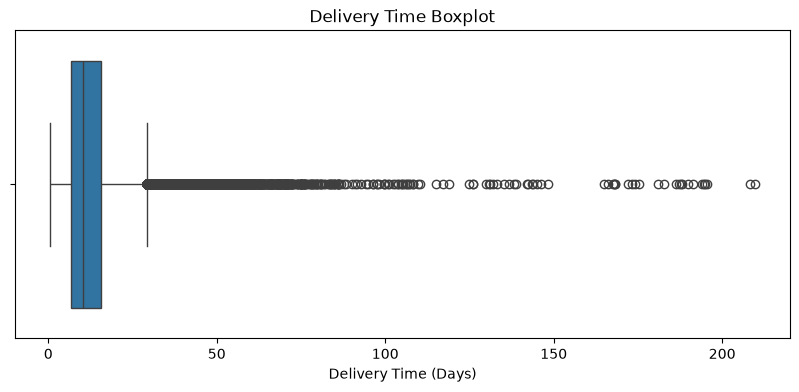

In [49]:
plt.figure(figsize=(10, 4))

sns.boxplot(
    x=orders["delivery_days"]
)

plt.title("Delivery Time Boxplot")
plt.xlabel("Delivery Time (Days)")

plt.show()

In [50]:
orders["delivery_days"].quantile(
    [0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
)

0.01     1.825023
0.05     3.014991
0.25     6.765498
0.50    10.216227
0.75    15.720145
0.95    29.273896
0.99    46.045586
Name: delivery_days, dtype: float64

In [51]:
orders["order_estimated_delivery_date"] = pd.to_datetime(
    orders["order_estimated_delivery_date"]
)

In [52]:
orders["order_delivered_customer_date"] = pd.to_datetime(
    orders["order_delivered_customer_date"]
)

In [53]:
orders["delivery_delay_days"] = (
    orders["order_delivered_customer_date"]
    -
    orders["order_estimated_delivery_date"]
).dt.total_seconds() / (60 * 60 * 24)

In [54]:
orders["delivery_delay_days"].describe()

count    96455.000000
mean       -11.176795
std         10.183950
min       -146.016123
25%        -16.243773
50%        -11.945069
75%         -6.389109
max        188.975081
Name: delivery_delay_days, dtype: float64

In [55]:
orders["late_delivery"] = (
    orders["delivery_delay_days"] > 0
).astype(int)

In [56]:
orders["late_delivery"].value_counts()

late_delivery
0    88630
1     7825
Name: count, dtype: int64

In [57]:
orders["late_delivery"].value_counts(
    normalize=True
) * 100

late_delivery
0    91.887409
1     8.112591
Name: proportion, dtype: float64

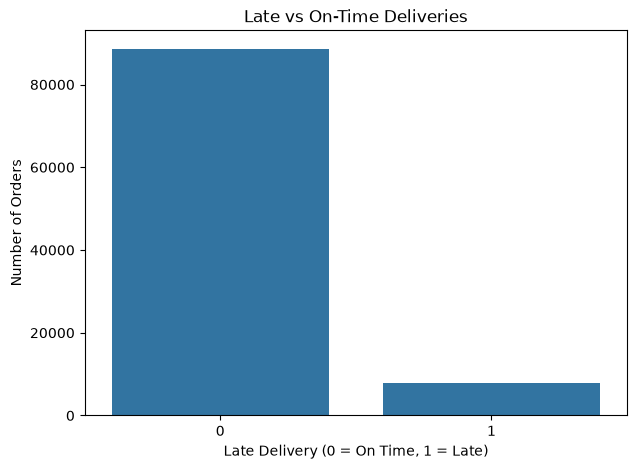

In [58]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=orders,
    x="late_delivery"
)

plt.title("Late vs On-Time Deliveries")
plt.xlabel("Late Delivery (0 = On Time, 1 = Late)")
plt.ylabel("Number of Orders")

plt.show()

In [59]:
reviews["review_score"].value_counts().sort_index()

review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64

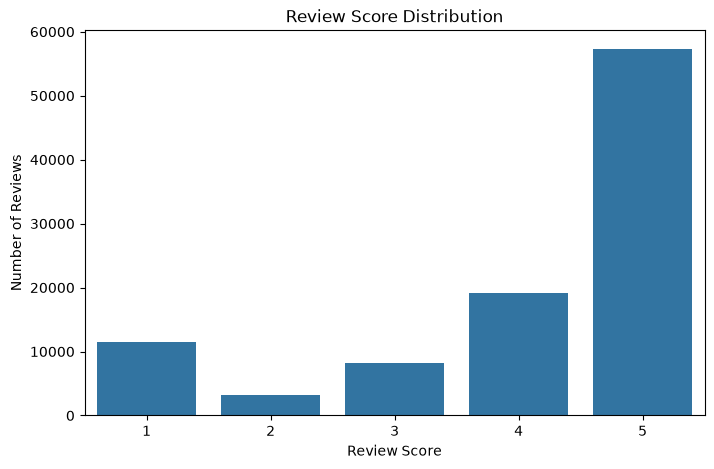

In [60]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=reviews,
    x="review_score"
)

plt.title("Review Score Distribution")
plt.xlabel("Review Score")
plt.ylabel("Number of Reviews")

plt.show()

In [61]:
reviews["review_score"].mean()

np.float64(4.08642062404257)

In [62]:
reviews["review_score"].median()

np.float64(5.0)

In [63]:
order_reviews = orders[
    [
        "order_id",
        "delivery_days",
        "delivery_delay_days",
        "late_delivery"
    ]
].merge(
    reviews[
        [
            "order_id",
            "review_score"
        ]
    ],
    on="order_id",
    how="inner"
)

In [64]:
order_reviews.head()

,order_id,delivery_days,delivery_delay_days,late_delivery,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,8.436574,-7.107488,0,4
1,53cdb2fc8bc7dce0b6741e2150273451,13.782037,-5.355729,0,4
2,47770eb9100c2d0c44946d9cf07ec65d,9.394213,-17.245498,0,5
3,949d5b44dbf5de918fe9c16f97b45f8a,13.208750,-12.980069,0,5
4,ad21c59c0840e6cb83a9ceb5573f8159,2.873877,-9.238171,0,5


In [65]:
order_reviews.groupby(
    "late_delivery"
)["review_score"].mean()

late_delivery
0    4.293708
1    2.566177
Name: review_score, dtype: float64

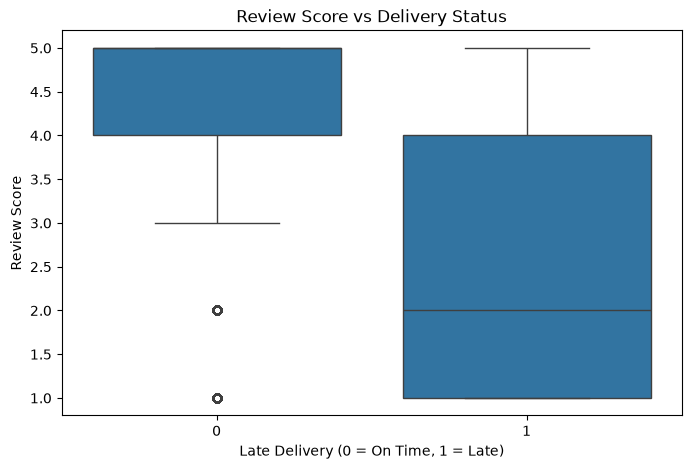

In [66]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=order_reviews,
    x="late_delivery",
    y="review_score"
)

plt.title("Review Score vs Delivery Status")
plt.xlabel("Late Delivery (0 = On Time, 1 = Late)")
plt.ylabel("Review Score")

plt.show()

In [67]:
order_items["price"].describe()

count    112650.000000
mean        120.653739
std         183.633928
min           0.850000
25%          39.900000
50%          74.990000
75%         134.900000
max        6735.000000
Name: price, dtype: float64

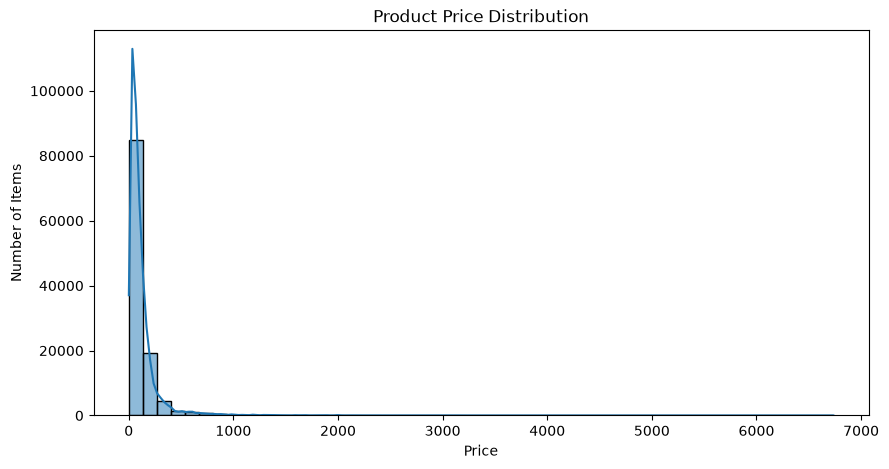

In [68]:
plt.figure(figsize=(10, 5))

sns.histplot(
    order_items["price"],
    bins=50,
    kde=True
)

plt.title("Product Price Distribution")
plt.xlabel("Price")
plt.ylabel("Number of Items")

plt.show()

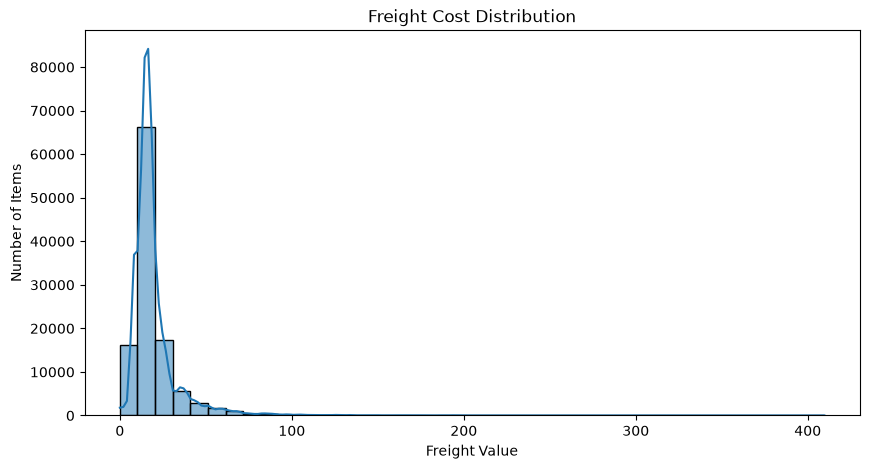

In [69]:
plt.figure(figsize=(10, 5))

sns.histplot(
    order_items["freight_value"],
    bins=40,
    kde=True
)

plt.title("Freight Cost Distribution")
plt.xlabel("Freight Value")
plt.ylabel("Number of Items")

plt.show()

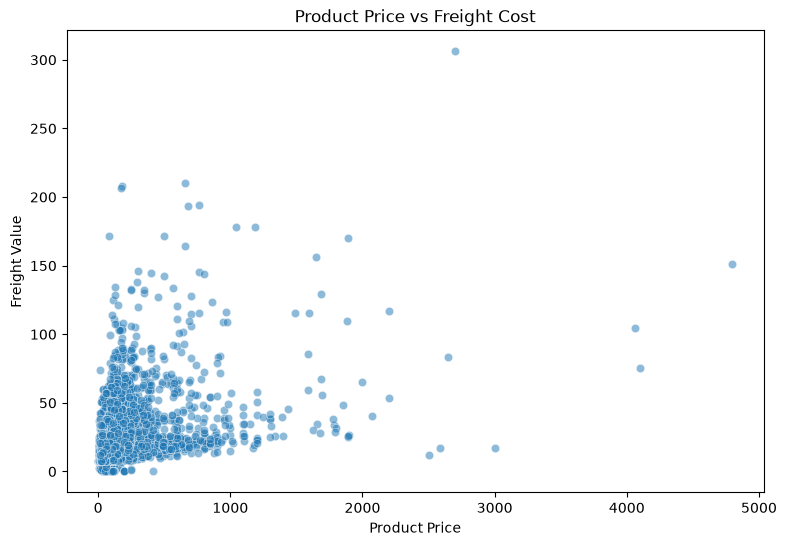

In [70]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=order_items.sample(
        min(10000, len(order_items)),
        random_state=42
    ),
    x="price",
    y="freight_value",
    alpha=0.5
)

plt.title("Product Price vs Freight Cost")
plt.xlabel("Product Price")
plt.ylabel("Freight Value")

plt.show()

In [71]:
products["product_category_name_english"].value_counts().head(15)

product_category_name_english
bed_bath_table              3029
sports_leisure              2867
furniture_decor             2657
health_beauty               2444
housewares                  2335
auto                        1900
computers_accessories       1639
toys                        1411
watches_gifts               1329
telephony                   1134
baby                         919
perfumery                    868
stationery                   849
fashion_bags_accessories     849
cool_stuff                   789
Name: count, dtype: int64

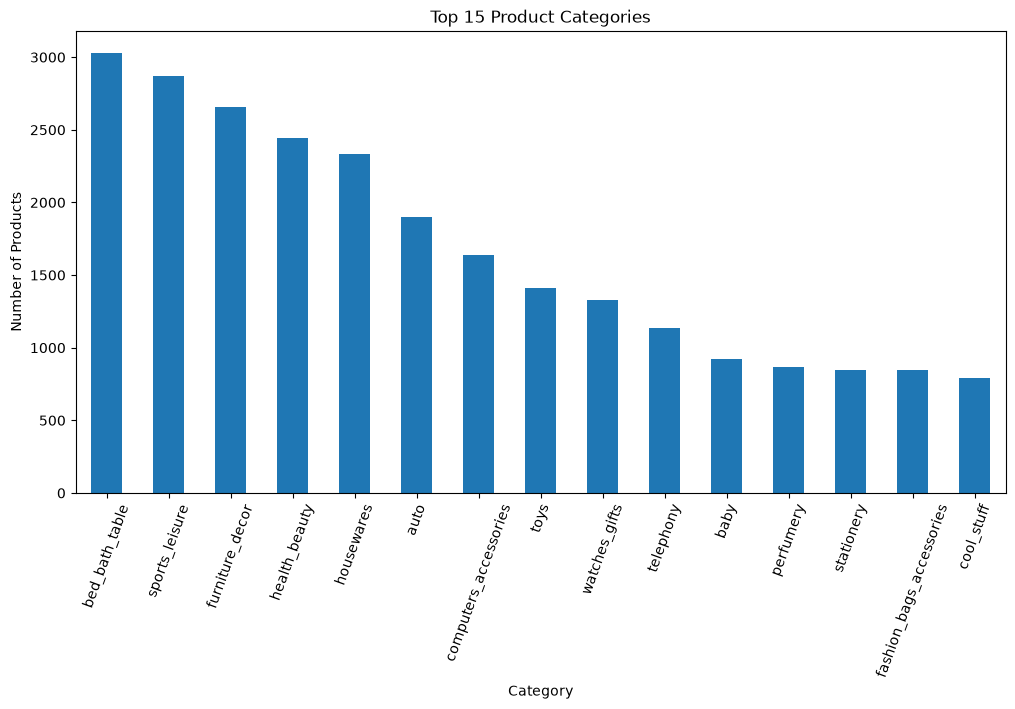

In [72]:
top_categories = (
    products["product_category_name_english"]
    .value_counts()
    .head(15)
)

plt.figure(figsize=(12, 6))

top_categories.plot(kind="bar")

plt.title("Top 15 Product Categories")
plt.xlabel("Category")
plt.ylabel("Number of Products")

plt.xticks(rotation=70)

plt.show()

In [73]:
customers["customer_state"].value_counts().head(15)

customer_state
SP    41746
RJ    12852
MG    11635
RS     5466
PR     5045
SC     3637
BA     3380
DF     2140
ES     2033
GO     2020
PE     1652
CE     1336
PA      975
MT      907
MA      747
Name: count, dtype: int64

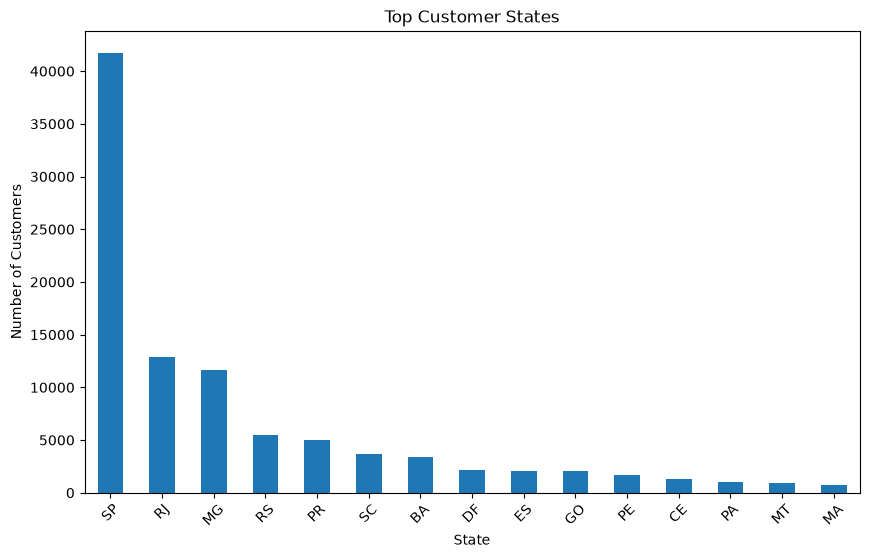

In [74]:
top_states = (
    customers["customer_state"]
    .value_counts()
    .head(15)
)

plt.figure(figsize=(10, 6))

top_states.plot(kind="bar")

plt.title("Top Customer States")
plt.xlabel("State")
plt.ylabel("Number of Customers")

plt.xticks(rotation=45)

plt.show()

In [75]:
sellers["seller_state"].value_counts().head(15)

seller_state
SP    1849
PR     349
MG     244
SC     190
RJ     171
RS     129
GO      40
DF      30
ES      23
BA      19
CE      13
PE       9
PB       6
RN       5
MS       5
Name: count, dtype: int64

In [76]:
numeric_cols = [
    "delivery_days",
    "delivery_delay_days"
]

orders[numeric_cols].corr()

,delivery_days,delivery_delay_days
delivery_days,1.00000,0.60742
delivery_delay_days,0.60742,1.00000


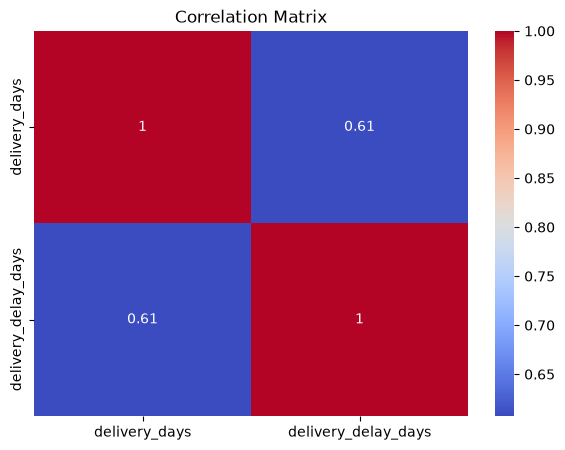

In [77]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    orders[numeric_cols].corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Matrix")

plt.show()

In [78]:
items_products = order_items.merge(
    products[
        [
            "product_id",
            "product_category_name_english"
        ]
    ],
    on="product_id",
    how="left"
)

In [79]:
category_delivery = items_products.merge(
    orders[
        [
            "order_id",
            "delivery_days",
            "late_delivery"
        ]
    ],
    on="order_id",
    how="inner"
)

In [80]:
category_delivery.groupby(
    "product_category_name_english"
)["delivery_days"].mean().sort_values(
    ascending=False
).head(15)

product_category_name_english
office_furniture                     20.841449
christmas_supplies                   15.740684
fashion_shoes                        15.441354
security_and_services                15.138154
home_comfort_2                       14.573525
furniture_mattress_and_upholstery    14.432970
home_appliances_2                    13.906447
furniture_living_room                13.795035
garden_tools                         13.708863
fashion_underwear_beach              13.706326
consoles_games                       13.610097
home_confort                         13.532880
computers                            13.508088
audio                                13.320865
furniture_bedroom                    13.244851
Name: delivery_days, dtype: float64

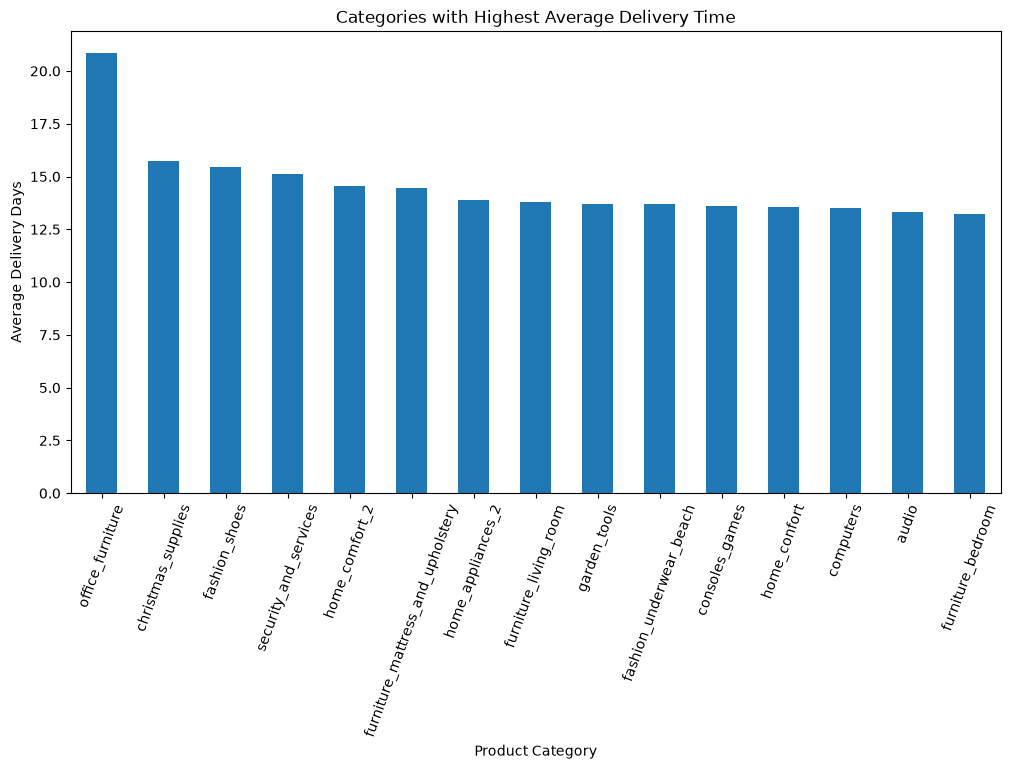

In [81]:
category_avg_delivery = (
    category_delivery
    .groupby("product_category_name_english")
    ["delivery_days"]
    .mean()
    .sort_values(ascending=False)
    .head(15)
)

plt.figure(figsize=(12, 6))

category_avg_delivery.plot(kind="bar")

plt.title("Categories with Highest Average Delivery Time")
plt.xlabel("Product Category")
plt.ylabel("Average Delivery Days")

plt.xticks(rotation=70)

plt.show()

In [82]:
category_late_rate = (
    category_delivery
    .groupby("product_category_name_english")
    ["late_delivery"]
    .mean()
    .sort_values(ascending=False)
)

In [83]:
category_late_rate = category_late_rate * 100

In [84]:
category_late_rate.head(15)

product_category_name_english
home_comfort_2                       16.666667
furniture_mattress_and_upholstery    13.513514
audio                                12.707182
fashion_underwear_beach              12.598425
christmas_supplies                   12.000000
books_technical                      11.026616
home_confort                         10.256410
construction_tools_lights             9.966777
food                                  9.819639
electronics                           9.747160
unknown                               9.306804
health_beauty                         9.054411
office_furniture                      8.932854
baby                                  8.786050
musical_instruments                   8.602151
Name: late_delivery, dtype: float64

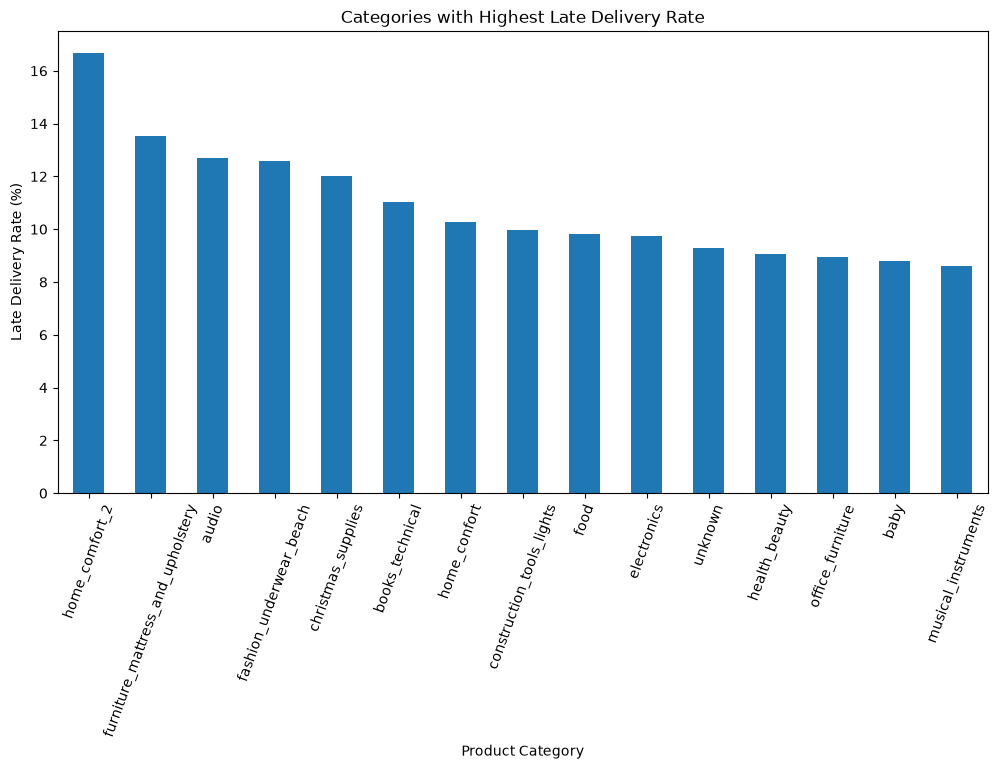

In [85]:
plt.figure(figsize=(12, 6))

category_late_rate.head(15).plot(kind="bar")

plt.title("Categories with Highest Late Delivery Rate")
plt.xlabel("Product Category")
plt.ylabel("Late Delivery Rate (%)")

plt.xticks(rotation=70)

plt.show()

In [86]:
category_stats = (
    category_delivery
    .groupby("product_category_name_english")
    .agg(
        orders=("order_id", "count"),
        late_rate=("late_delivery", "mean"),
        avg_delivery_days=("delivery_days", "mean")
    )
)

In [87]:
category_stats[
    category_stats["orders"] >= 100
].sort_values(
    "late_rate",
    ascending=False
).head(15)

,orders,late_rate,avg_delivery_days
product_category_name_english,,,
audio,362,0.127072,13.320865
fashion_underwear_beach,127,0.125984,13.706326
christmas_supplies,150,0.120000,15.740684
books_technical,263,0.110266,10.653127
home_confort,429,0.102564,13.532880
construction_tools_lights,301,0.099668,9.724349
food,499,0.098196,9.559812
electronics,2729,0.097472,12.885882
unknown,1558,0.093068,12.734784
